# 3.C EOQ

Hieronder illustreren we de kracht van NumPy in de context van supply chain management.

Een veelgebruikt begrip in SCM is de Economic Order Quantity (EOQ) die wordt berekend als volgt: $EOQ=\sqrt{\frac{2 * D * S}{H}}$ waarbij $D$ staat voor de jaarlijkse vraag, $S$ voor bestelkosten per bestelling en $H$ voor de voorraadkosten per jaar.

Vanuit het EOQ kunnen we dan de bestelkosten berekenen (vraag gedeeld door bestelhoeveelheid):
$$B= \frac{D}{EOQ} * S$$
en de voorraadkosten (bestelhoeveelheid gedeeld door 2 om de gemiddelde voorraad te benaderen):
$$V = \frac{EOQ}{2} * H$$

We kunnen NumPy gebruiken om snel een grote hoeveelheid aan bestelhoeveelheden te vinden en daaruit de beste, de EOQ, te vinden en te visualiseren. We doen dit door gebruik te maken van de automatische matrix-vermenigvuldiging zodat we snel een groot aantal bestelhoeveelheden kunnen verkrijgen. Eerst berekenen we een enkele EOQ:

In [1]:
import numpy as np 

D = 10000 
S = 50    
H = 2     

EOQ = np.sqrt((2 * D * S) / H)
bestelkosten = (D / EOQ) * S
voorraadkosten = (EOQ / 2) * H
totale_kosten = bestelkosten + voorraadkosten

print(f"EOQ:\t\t {EOQ:.2f} eenheden")
print(f"Bestelkosten:\t €{bestelkosten:.2f}")
print(f"Voorraadkosten:\t €{voorraadkosten:.2f}")
print(f"Totale kosten:\t €{totale_kosten:.2f}")

EOQ:		 707.11 eenheden
Bestelkosten:	 €707.11
Voorraadkosten:	 €707.11
Totale kosten:	 €1414.21


Nu gebruiken we `arange` om een groot aantal $S$- en $H$-waarden te bekomen en deze te gebruiken in een matrix van bestelhoeveelheden:

In [2]:
S_waarden = np.arange(10, 100, 10)  # reeks van bestelkosten
H_waarden = np.arange(1, 5, 0.5)    # reeks van voorraadkosten

print('Bestelkosten:', S_waarden)
print('Voorraadkosten:', H_waarden)

Bestelkosten: [10 20 30 40 50 60 70 80 90]
Voorraadkosten: [1.  1.5 2.  2.5 3.  3.5 4.  4.5]


Hieruit kunnen we een hele matrix met kosten als rijen en voorraadhoevelheden als kolommen berekenen. Om dit te laten werken moeten we wel de bestelkosten omzetten in een matrix via `reshape` zodat die een matrix met 1 kolom wordt:

In [3]:
EOQ_matrix = np.sqrt((2 * D * np.reshape(S_waarden, (len(S_waarden),1)) / H_waarden))

print("\nEOQ voor verschillende S en H (rijen: S, kolommen: H):")
EOQ_matrix


EOQ voor verschillende S en H (rijen: S, kolommen: H):


array([[ 447.2135955 ,  365.14837167,  316.22776602,  282.84271247,
         258.19888975,  239.04572187,  223.60679775,  210.81851068],
       [ 632.45553203,  516.39777949,  447.2135955 ,  400.        ,
         365.14837167,  338.06170189,  316.22776602,  298.142397  ],
       [ 774.59666924,  632.45553203,  547.72255751,  489.89794856,
         447.2135955 ,  414.03933561,  387.29833462,  365.14837167],
       [ 894.427191  ,  730.29674334,  632.45553203,  565.68542495,
         516.39777949,  478.09144373,  447.2135955 ,  421.63702136],
       [1000.        ,  816.49658093,  707.10678119,  632.45553203,
         577.35026919,  534.52248382,  500.        ,  471.40452079],
       [1095.44511501,  894.427191  ,  774.59666924,  692.82032303,
         632.45553203,  585.54004377,  547.72255751,  516.39777949],
       [1183.21595662,  966.09178308,  836.66002653,  748.33147735,
         683.13005106,  632.45553203,  591.60797831,  557.77335102],
       [1264.91106407, 1032.79555899,  89

Nu gaan we aan de slag met Matplotlib (zit ook standaard in de Python-installatie van Anaconda) om dit te visualiseren. Matplotlib sluit naadloos aan bij NumPy en Pandas (maar is **niet** te kennen voor het examen). Hieronder plotten we de bestelhoeveelheden voor verschillende $D$ en $S$ waarden die we aanmaakten met `np.arange()`:

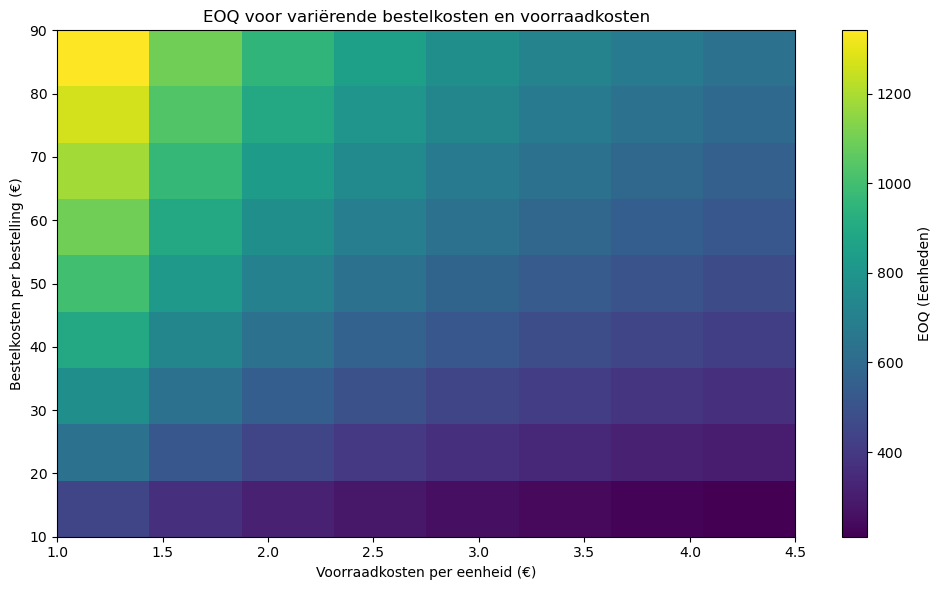

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.imshow(EOQ_matrix, aspect='auto', cmap='viridis', origin='lower', 
           extent=[H_waarden[0], H_waarden[-1], S_waarden[0], S_waarden[-1]])
plt.colorbar(label='EOQ (Eenheden)')
plt.xlabel('Voorraadkosten per eenheid (€)')
plt.ylabel('Bestelkosten per bestelling (€)')
plt.title('EOQ voor variërende bestelkosten en voorraadkosten')
plt.tight_layout()

plt.show()

Als laatste gaan we ook de bestel- en voorraadkosten berekenen en visualiseren zodat we meteen kunnen zien waar de beste EOQ ligt. We gebruiken weer `arange` om een aantal bestelhoeveelheden aan te maken en berekenen daarna terug de bestelkosten en voorraadkosten. De berekingen met de vectoren is identiek aan die van de enkele getallen want NumPy zal in de achtergrond de juiste vectoriële berekeningen maken:

In [5]:
bestel_hoeveelheden = np.arange(100, 1000, 50)  
bestelkosten = (D / bestel_hoeveelheden) * S  
voorraadkosten = (bestel_hoeveelheden / 2) * H  
totale_kosten = bestelkosten + voorraadkosten  
totale_kosten

array([5100.        , 3483.33333333, 2700.        , 2250.        ,
       1966.66666667, 1778.57142857, 1650.        , 1561.11111111,
       1500.        , 1459.09090909, 1433.33333333, 1419.23076923,
       1414.28571429, 1416.66666667, 1425.        , 1438.23529412,
       1455.55555556, 1476.31578947])

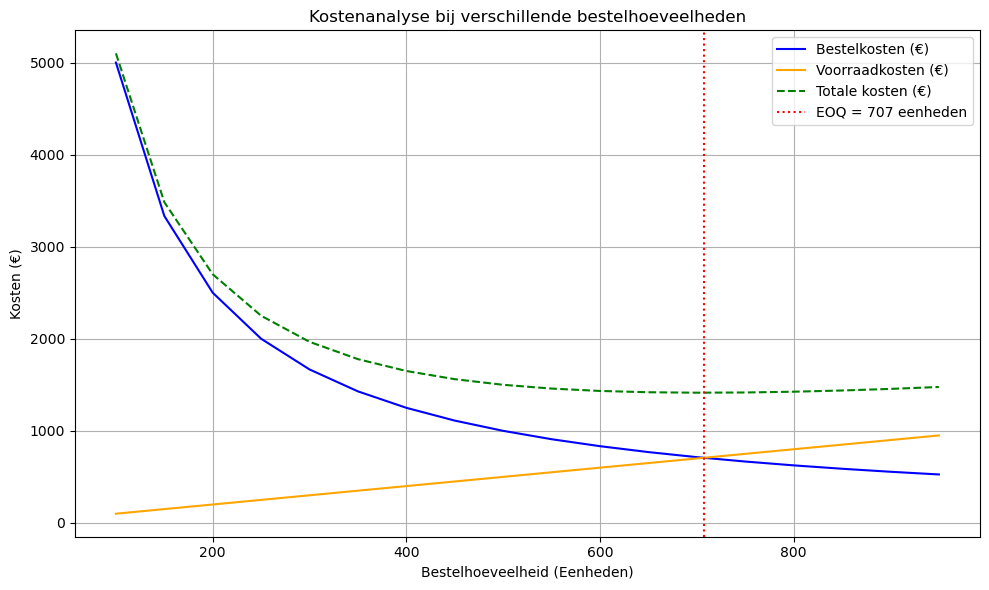

In [6]:
plt.figure(figsize=(10, 6))
plt.plot(bestel_hoeveelheden, bestelkosten, label='Bestelkosten (€)', color='blue')
plt.plot(bestel_hoeveelheden, voorraadkosten, label='Voorraadkosten (€)', color='orange')
plt.plot(bestel_hoeveelheden, totale_kosten, label='Totale kosten (€)', color='green', linestyle='--')
plt.axvline(EOQ, color='red', linestyle=':', label=f'EOQ = {EOQ:.0f} eenheden')
plt.xlabel('Bestelhoeveelheid (Eenheden)')
plt.ylabel('Kosten (€)')
plt.title('Kostenanalyse bij verschillende bestelhoeveelheden')
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()